# Lab 15 solution: keep the totals out of the model's code, and test the container's limits

This notebook solves the two Challenge tasks of lab 15. It repeats the setup it needs (the config cell, the read-only
database, the container runner, the hosted runner and the chart agent, as in the lab), so it runs on its own.

## Setup

In [1]:
from pathlib import Path
import base64
import difflib
import json
import os
import re
import shutil
import sqlite3
import subprocess
import sys
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


In [2]:
from IPython.display import Image, display
from openai import OpenAI, omit

client = OpenAI()
LAB = ROOT / "15_Code_Execution"
OUTPUTS = LAB / "outputs"          # everything this notebook writes; git ignores this folder
OUTPUTS.mkdir(exist_ok=True)

# The shop's database, opened read-only: no query can change it
DB_PATH = ROOT / "data" / "chinook.db"
conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True, check_same_thread=False)

# Prices in US dollars per token, from models.env
PRICE_IN = float(settings["PRICE_INPUT_PER_MILLION"]) / 1e6
PRICE_CACHED = float(settings["PRICE_CACHED_INPUT_PER_MILLION"]) / 1e6
PRICE_WRITE = float(settings["PRICE_CACHE_WRITE_PER_MILLION"]) / 1e6
PRICE_OUT = float(settings["PRICE_OUTPUT_PER_MILLION"]) / 1e6
CONTAINER_SESSION_USD = float(settings["PRICE_CONTAINER_SESSION_USD"])  # one hosted 1 GB container, per 20-minute session


def price(input_tokens, cached, written, output_tokens):
    """Dollars for one call: ordinary input, cached input, cache writes and output, each at its own price."""
    ordinary = input_tokens - cached - written
    return ordinary * PRICE_IN + cached * PRICE_CACHED + written * PRICE_WRITE + output_tokens * PRICE_OUT


print("lab folder:", LAB.relative_to(ROOT), "| outputs:", OUTPUTS.relative_to(ROOT))
print("invoices in the database:", conn.execute("SELECT COUNT(*) FROM invoices").fetchone()[0])

lab folder: 15_Code_Execution | outputs: 15_Code_Execution/outputs
invoices in the database: 412


In [3]:
YEARLY_SQL = """
SELECT strftime('%Y', InvoiceDate) AS year, ROUND(SUM(Total), 2) AS revenue
FROM invoices
GROUP BY year
ORDER BY year
"""
TRUTH = dict(conn.execute(YEARLY_SQL).fetchall())
print(TRUTH)

{'2009': 449.46, '2010': 481.45, '2011': 469.58, '2012': 477.53, '2013': 450.58}


The two runners from Parts C and D, unchanged: the container (when Docker is running) and the hosted code
interpreter.

In [4]:
DOCKER_OK = False
if shutil.which("docker") is None:
    print("docker: not installed. The container cells will skip; run_python will use the hosted sandbox.")
else:
    info = subprocess.run(["docker", "info", "--format", "{{.ServerVersion}}"], capture_output=True, text=True)
    DOCKER_OK = info.returncode == 0
    print("docker server:", info.stdout.strip() if DOCKER_OK else info.stderr.strip()[:200])
SKIP = "Docker is not available: skipped. The saved output shows our run."

docker server: 29.9.1


In [5]:
if DOCKER_OK:
    build = subprocess.run(["docker", "build", "--quiet", "--tag", "chinook-sandbox", str(LAB / "resources")],
                           capture_output=True, text=True)
    print("built:", build.returncode == 0)
else:
    print(SKIP)

built: True


In [6]:
SANDBOX_FLAGS = [
    "--rm",                                         # delete the container when the code ends
    "--network", "none",                            # no network at all
    "--read-only",                                  # the image's own files cannot be changed
    "--tmpfs", "/tmp",                              # ... except an empty /tmp, kept in memory
    "--memory", "256m", "--memory-swap", "256m",    # 256 MB of memory, and no swap on top of it
    "--cpus", "1",                                  # at most one CPU
    "--pids-limit", "64",                           # at most 64 processes, so code cannot start them without end
    "--cap-drop", "ALL",                            # none of the special powers Linux gives root
    "--security-opt", "no-new-privileges",          # no way to gain more rights while it runs
]
MOUNT = ["--volume", f"{OUTPUTS}:/work"]           # our outputs folder appears as /work; nothing else of ours does
OUTPUTS.chmod(0o777)                                # the container's user is not you: let it write in this one folder
print(len(SANDBOX_FLAGS), "flag values, one folder mounted at /work")

18 flag values, one folder mounted at /work


In [7]:
def run_in_container(code):
    """Run Python code in the sandbox container; return what it printed."""
    (OUTPUTS / "run.py").write_text(code)
    result = subprocess.run(
        ["docker", "run", *SANDBOX_FLAGS, *MOUNT, "chinook-sandbox", "timeout", "20", "python", "run.py"],
        capture_output=True, text=True,
    )
    printed = result.stdout + result.stderr
    return printed[-2000:] if printed else f"finished with exit code {result.returncode}, printed nothing"

In [8]:
HOSTED_CONTAINER = {"type": "auto", "memory_limit": "1g", "network_policy": {"type": "disabled"}}
RUN_AS_WRITTEN = ("Run the user's Python code with the python tool exactly as written, once, without changing it. "
                  "Then reply with what it printed.")

In [9]:
hosted_runs = []     # every hosted run: the code we sent, the code that ran, and the usage


def run_hosted(code):
    """Run Python code in OpenAI's hosted code interpreter; return what it printed."""
    response = client.responses.create(
        model=MODEL,
        reasoning={"effort": EFFORT or omit},
        instructions=RUN_AS_WRITTEN,
        input=code,
        tools=[{"type": "code_interpreter", "container": HOSTED_CONTAINER}],
        tool_choice="required",
        include=["code_interpreter_call.outputs"],
    )
    call = next(item for item in response.output if item.type == "code_interpreter_call")
    hosted_runs.append({"sent": code, "ran": call.code, "usage": response.usage})
    printed, charts = "", 0
    for output in call.outputs or []:
        if output.type == "logs":
            printed += output.logs
        if output.type == "image":            # a chart comes back as a PNG inside a data URL
            charts += 1
            png = base64.b64decode(output.url.split(",", 1)[1])
            (OUTPUTS / f"hosted_chart_{charts}.png").write_bytes(png)
    if call.code.strip() != code.strip():
        printed = "Warning: the hosted runner changed the code before running it.\n" + printed
    return printed + (f"[{charts} chart(s) saved]" if charts else "")

## Task 1: Keep the totals out of the model's code

Three changes to Part E's tools:

1. `run_sql` keeps the rows of its last successful query in `last_rows`. `global last_rows` lets the function replace
   the variable defined outside it, instead of making a new local one.
2. `run_python` puts one line before the model's code: `rows = ` and the rows as JSON. JSON writes a list of lists
   that is also valid Python (`[["2009", 449.46], ...]`), so the code starts with `rows` already defined. The numbers
   in that line are written by our code from the database, never typed by the model.
3. The description of `run_python` tells the model that `rows` is there, and that it must use it.

The container and hosted branches, and the refusal, stay as they were.

In [10]:
last_rows = []


def run_sql(query):
    """Run one read-only query; keep its rows for run_python; return up to 50 rows as JSON."""
    global last_rows
    try:
        last_rows = conn.execute(query).fetchmany(50)
        return json.dumps(last_rows)
    except sqlite3.Error as error:
        return f"SQLite error: {error}"


USE_HOSTED = True


def run_python(code):
    """Run code in a sandbox with the last query's rows defined as `rows`, or refuse."""
    code = f"rows = {json.dumps(last_rows)}\n" + code
    if DOCKER_OK:
        return run_in_container(code)
    if USE_HOSTED:
        return run_hosted(code)
    return ("Not run: no sandbox is available (Docker is not running and the hosted runner is switched off). "
            "This tool never runs code on this machine.")

In [11]:
TOOLS = [
    {"type": "function", "function": {
        "name": "run_sql",
        "description": "Run one read-only SQLite query on the Chinook shop database and return up to 50 rows as JSON.",
        "parameters": {"type": "object", "properties": {"query": {"type": "string"}},
                       "required": ["query"], "additionalProperties": False}}},
    {"type": "function", "function": {
        "name": "run_python",
        "description": ("Run Python code with matplotlib in a sandbox and return what it printed. "
                        "The sandbox has no database and no network; save files in the working folder. "
                        "A variable named rows already holds the rows of your last run_sql result, as a list of lists: "
                        "use it, and never type the numbers into the code."),
        "parameters": {"type": "object", "properties": {"code": {"type": "string"}},
                       "required": ["code"], "additionalProperties": False}}},
]
SYSTEM = "You are the Chinook music shop's data assistant. Use run_sql to read the database and run_python to draw charts."
QUESTION = "Make a bar chart of the shop's revenue by year and save it as revenue_by_year.png."
print([tool["function"]["name"] for tool in TOOLS])

['run_sql', 'run_python']


In [12]:
agent_usage = []      # the usage of every model call the agent makes


def ask_chart_agent(question, max_turns=8):
    """The loop from lab 04: call the model, run the tools it asks for, send the results back, until it answers."""
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": question}]
    steps = []
    for turn in range(max_turns):
        reply = client.chat.completions.create(
            model=MODEL, messages=messages, tools=TOOLS,
            reasoning_effort=EFFORT or omit, max_completion_tokens=1500,
        )
        agent_usage.append(reply.usage)
        message = reply.choices[0].message
        messages.append(message)
        if not message.tool_calls:
            return message.content, steps
        for call in message.tool_calls:
            arguments = json.loads(call.function.arguments)
            if call.function.name == "run_sql":
                result = run_sql(arguments["query"])
            else:
                result = run_python(arguments["code"])
            steps.append((call.function.name, arguments, result))
            messages.append({"role": "tool", "tool_call_id": call.id, "content": result})
    return "Stopped: no answer within the turn limit.", steps

In [13]:
def totals_typed_in(code):
    """How many of the five true yearly totals appear as numbers typed into the code."""
    typed = {round(float(number), 2) for number in re.findall(r"\d+\.\d+", code)}
    return sum(revenue in typed for revenue in TRUTH.values())


codes = []
for number in range(1, 4):
    (OUTPUTS / "revenue_by_year.png").unlink(missing_ok=True)
    answer, steps = ask_chart_agent(QUESTION)
    code = [arguments["code"] for name, arguments, result in steps if name == "run_python"][-1]
    codes.append(code)
    print(f"run {number}: totals typed in {totals_typed_in(code)} of 5 | uses rows: {'rows' in code} | answer: {answer[:70]}")
print("rows the code received:", last_rows)

run 1: totals typed in 0 of 5 | uses rows: True | answer: Created the bar chart and saved it as **revenue_by_year.png**.


run 2: totals typed in 0 of 5 | uses rows: True | answer: Created the bar chart and saved it as **revenue_by_year.png**.


run 3: totals typed in 0 of 5 | uses rows: True | answer: Created the bar chart and saved it as **revenue_by_year.png**.
rows the code received: [('2009', 449.46), ('2010', 481.45), ('2011', 469.58), ('2012', 477.53), ('2013', 450.58)]


`0 of 5` in all three runs: the code used `rows` every time, and the model typed none of the totals. The rows the code received are the five of Part A, read from the database by our code.

The code of the last run, as the model wrote it (our `rows = ...` line is added in front of it when it runs):

In [14]:
print(codes[-1])

import matplotlib.pyplot as plt
# rows contains the result of the last SQL query
years = [row[0] for row in rows]
revenue = [row[1] for row in rows]
plt.figure(figsize=(8, 5))
plt.bar(years, revenue, color='steelblue')
plt.title("Chinook Shop Revenue by Year")
plt.xlabel("Year")
plt.ylabel("Revenue")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))
plt.tight_layout()
plt.savefig('revenue_by_year.png', dpi=150)
print('Saved revenue_by_year.png')


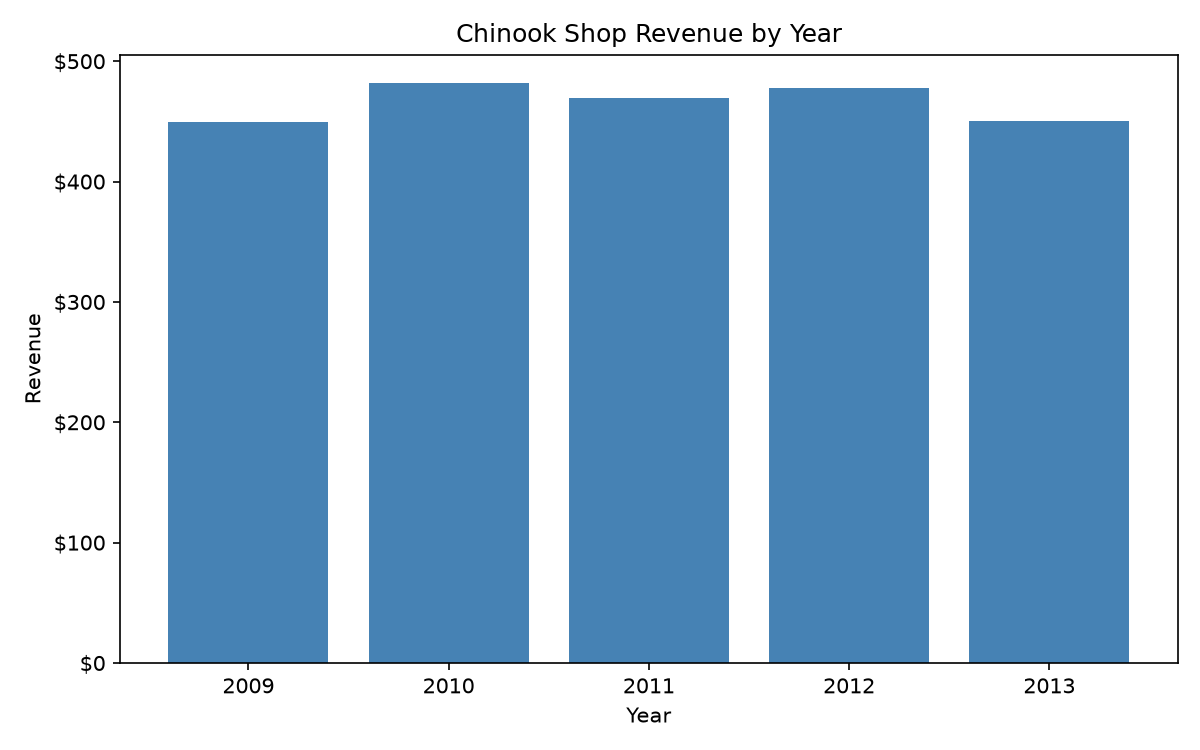

In [15]:
chart = OUTPUTS / "revenue_by_year.png" if DOCKER_OK else OUTPUTS / "hosted_chart_1.png"
display(Image(filename=chart, width=560))

`years = [row[0] for row in rows]` and `revenue = [row[1] for row in rows]` build the two lists from `rows`; the code holds no decimal number at all. The chart shows the same five bars as the reference chart, and the numbers now go from the database to the chart through our code only. `0 of 5` says the model typed no total; that the code used `rows` is what the `uses rows` check and the chart say.

## Task 2: Test the container's limits

Two probes of our own, sent through `run_in_container`, which runs each with Part C's flags and `timeout 20`. Both are
fixed text we wrote, like the probe in Part B. The endless loop takes the full 20 seconds before `timeout` stops it.

In [16]:
if DOCKER_OK:
    print("endless loop:", run_in_container("while True:\n    pass\n"))
    print("300 MB:      ", run_in_container("data = b'x' * (300 * 1024 * 1024)\nprint('allocated', len(data))\n"))
else:
    print(SKIP)

endless loop: finished with exit code 124, printed nothing
300 MB:       finished with exit code 137, printed nothing


The loop gave `finished with exit code 124, printed nothing`, and the 300 MB object `finished with exit code 137, printed nothing`.

- **124** is the exit code `timeout` uses when it had to stop the program: the 20-second limit at the end of the
  command, not a Docker flag, stopped the loop.
- **137** is 128 + 9: the program was killed with signal 9 (`SIGKILL`). The kernel's out-of-memory killer sent it
  when the container passed `--memory 256m`; `--memory-swap 256m` gave it no swap to spill into, so 300 MB could not
  fit. Without `--memory-swap`, Docker lets a container use as much swap again as its memory on a host that has
  swap, and the same program could finish.

Neither probe printed anything: both were stopped before their `print`, and the container was deleted afterwards
(`--rm`).